In [78]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import os


In [79]:
data_path=os.path.join('..', 'data', 'raw', 'AEP_hourly.csv')
df=pd.read_csv(data_path)
df.head(10)

,Datetime,AEP_MW
0,2004-12-31 01:00:00,13478.0
1,2004-12-31 02:00:00,12865.0
2,2004-12-31 03:00:00,12577.0
3,2004-12-31 04:00:00,12517.0
4,2004-12-31 05:00:00,12670.0
5,2004-12-31 06:00:00,13038.0
6,2004-12-31 07:00:00,13692.0
7,2004-12-31 08:00:00,14297.0
8,2004-12-31 09:00:00,14719.0
9,2004-12-31 10:00:00,14941.0


# Thông tin data

In [80]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 121273 entries, 0 to 121272
Data columns (total 2 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   Datetime  121273 non-null  object 
 1   AEP_MW    121273 non-null  float64
dtypes: float64(1), object(1)
memory usage: 1.9+ MB


## xử lý dữ liệu 

In [81]:
#ép sang datetime
df['Datetime'] = pd.to_datetime(df['Datetime'])
df=df.set_index('Datetime').sort_index()
df.columnd=['MW']
print(f"index : {df.index.min()} -> {df.index.max()}")
print(f"total hour : {len(df):,}")
print(f"total year : {(df.index.max() - df.index.min()).days/365:.1f} year")


index : 2004-10-01 01:00:00 -> 2018-08-03 00:00:00
total hour : 121,273
total year : 13.8 year


C:\Users\Windows\AppData\Local\Temp\ipykernel_7260\997615639.py:4: UserWarning: Pandas doesn't allow columns to be created via a new attribute name - see https://pandas.pydata.org/pandas-docs/stable/indexing.html#attribute-access
  df.columnd=['MW']


## Thống kê mô tả

In [82]:
df.describe()

,AEP_MW
count,121273.000000
mean,15499.513717
std,2591.399065
min,9581.000000
25%,13630.000000
50%,15310.000000
75%,17200.000000
max,25695.000000


Xử lý data

In [84]:
dpt=df.index.duplicated().sum()
print(f" Duplicated index: {dpt}")
#xử lý 
if dpt>0:
    df=df[~df.index.duplicated(keep='first')]
    print(f"Xóa {dpt} duplicated trong data")
#sắp xếp lại bản ghi
before_hours=int((df.index.max()-df.index.min()).total_seconds()/3600)+1
affter_hours=len(df)#số bản ghi sau khi xử lý
print(f"Before hours : {before_hours:,}")
print(f"Affter hours : {affter_hours}")
print(f"Missing hours : {before_hours-affter_hours}")

 Duplicated index: 0
Before hours : 121,296
Affter hours : 121269
Missing hours : 27


## Trực quan hóa data

C:\Users\Windows\AppData\Local\Temp\ipykernel_7260\488672156.py:47: FutureWarning: last is deprecated and will be removed in a future version. Please create a mask and filter using `.loc` instead
  last_year=df.last('365D')
C:\Users\Windows\AppData\Local\Temp\ipykernel_7260\488672156.py:53: FutureWarning: last is deprecated and will be removed in a future version. Please create a mask and filter using `.loc` instead
  last_week=df.last('7D')


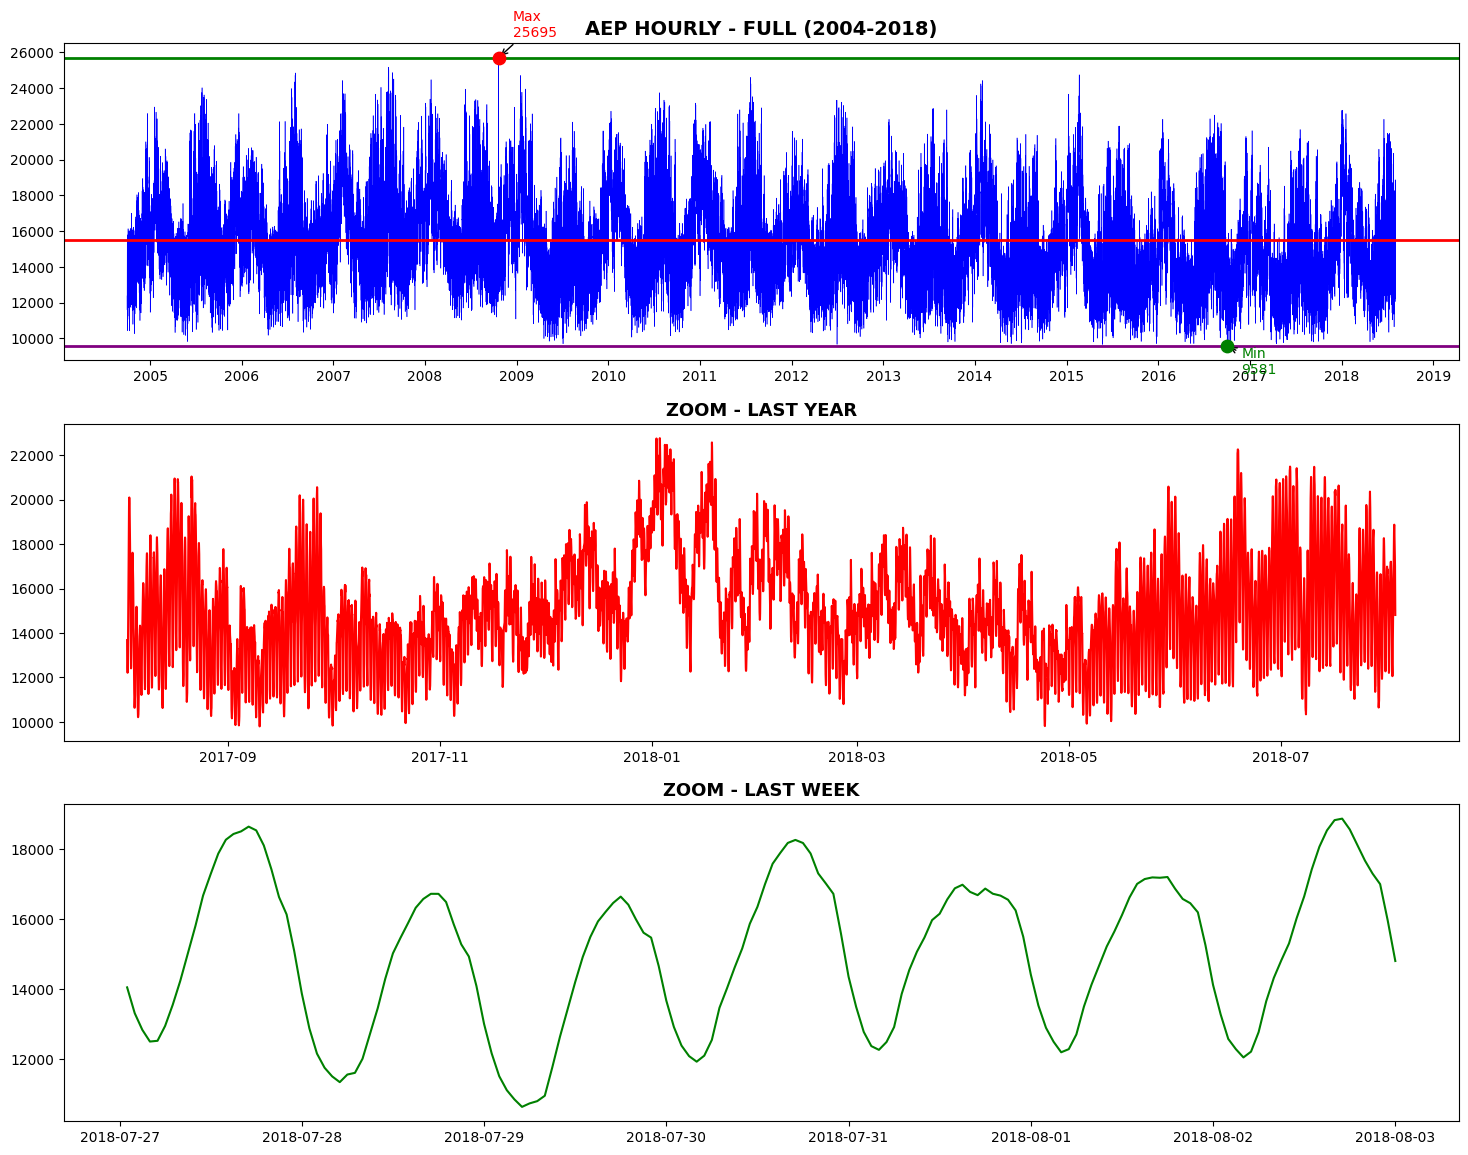

In [113]:
fig, axes=plt.subplots(3,1, figsize=(18,14))
#toàn bộ chuỗi thời gian
#thống kê 
mean_val=df['AEP_MW'].mean()
min_val=df['AEP_MW'].min()
max_val=df['AEP_MW'].max()

axes[0].plot(df.index, df['AEP_MW'], lw=0.4, color='blue')
axes[0].set_title('AEP HOURLY - FULL (2004-2018)', fontsize=14, fontweight='bold')
axes[0].set_label('AEP_MW')
# Mean
axes[0].axhline(mean_val,color='red',
                lw=2,label=f'Mean = {mean_val:.0f}')
# Max
axes[0].axhline(max_val,color='green',
                lw=2,label=f'Max = {max_val:.0f}')

# Min
axes[0].axhline(min_val,color='purple',
                lw=2,label=f'Min = {min_val:.0f}')

# Vị trí Min và Max
min_idx = df['AEP_MW'].idxmin()
max_idx = df['AEP_MW'].idxmax()
# Vẽ điểm
axes[0].scatter(max_idx,max_val,
               color='red',s=80,zorder=5)

axes[0].scatter(min_idx,min_val,
                color='green',s=80,zorder=5)

# Ghi chú
axes[0].annotate(f'Max\n{max_val:.0f}',(max_idx, max_val),xytext=(10,15),
                 textcoords='offset points',color='red',fontsize=10,
                 arrowprops=dict(arrowstyle='->'))

axes[0].annotate(f'Min\n{min_val:.0f}',(min_idx, min_val),xytext=(10,-20),
                 textcoords='offset points',color='green',fontsize=10,
                 arrowprops=dict(arrowstyle='->'))

# Định dạng trục X chỉ hiện năm (ví dụ: 2004, 2005,...)
axes[0].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
axes[0].xaxis.set_major_locator(mdates.YearLocator())   # Đánh dấu mỗi năm

#trực quan 365 ngày 
last_year=df.last('365D')
axes[1].plot(last_year.index, last_year['AEP_MW'], color='red')
axes[1].set_title('ZOOM - LAST YEAR', fontsize=13, fontweight='bold')
axes[1].set_label('AEP_MW')

#trực quan theo tuần 
last_week=df.last('7D')
axes[2].plot(last_week.index, last_week['AEP_MW'], color='green')
axes[2].set_title('ZOOM - LAST WEEK', fontsize=13, fontweight='bold')
axes[2].set_label('AEP_MW')

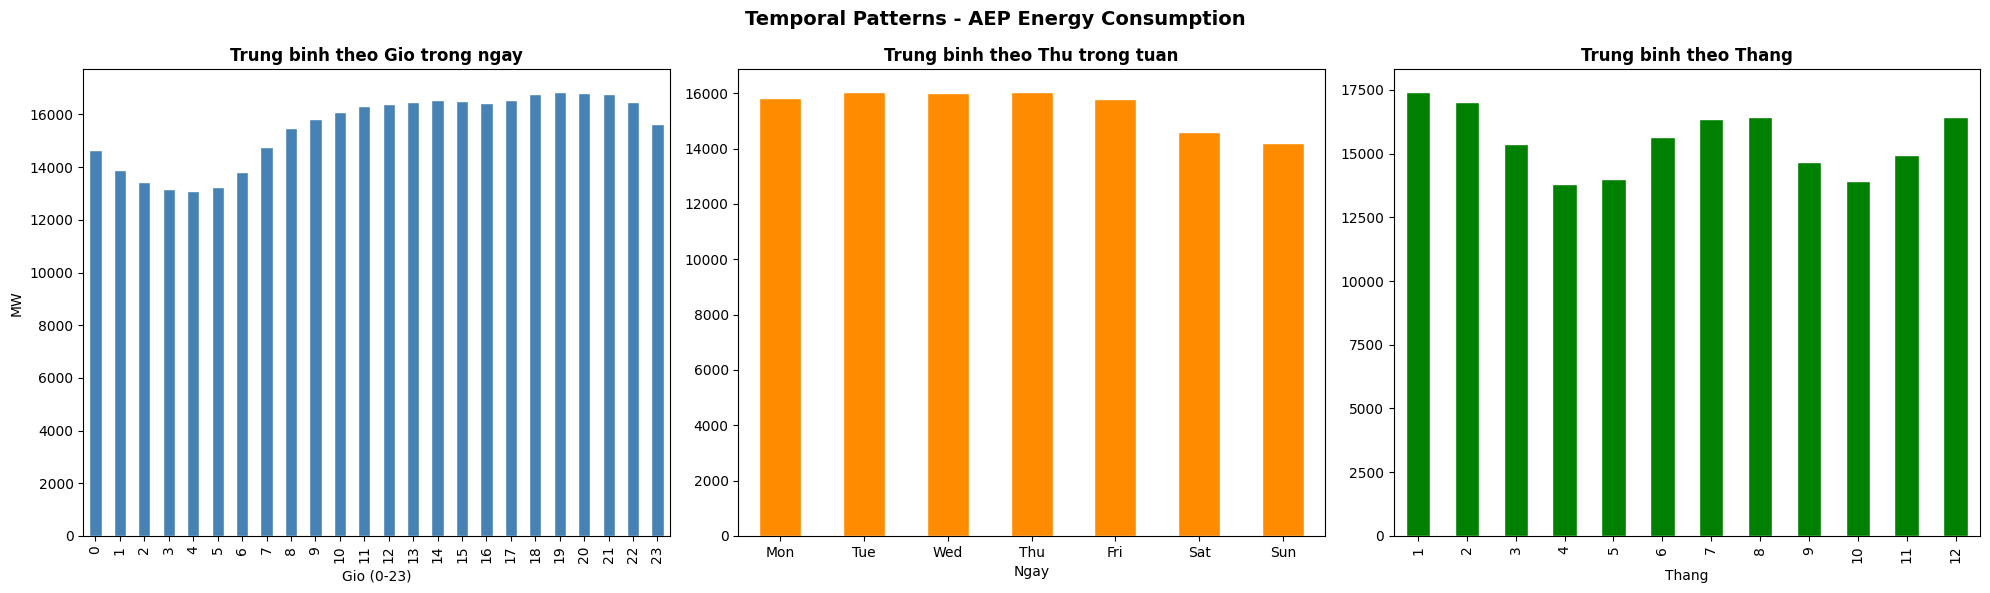

Peak hour    : 19h (gio cao diem)
Off-peak hour: 4h (gio thap diem)
Peak month   : 1 (thang tieu thu nhieu nhat)
Saved: ..\data\raw\AEP_cleaned.csv
Shape : (121269, 1)


In [112]:
df_eda = df.copy()
# Trích xuất các thành phần thời gian từ index (DatetimeIndex)
df_eda['hour']  = df_eda.index.hour       
df_eda['dow']   = df_eda.index.dayofweek   
df_eda['month'] = df_eda.index.month    
df_eda['year']  = df_eda.index.year         
# Tạo figure với 3 biểu đồ nằm ngang
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
fig.suptitle('Temporal Patterns - AEP Energy Consumption', fontsize=14, fontweight='bold')

df_eda.groupby('hour')['AEP_MW'].mean().plot(kind='bar', ax=axes[0],
                                          color='steelblue', edgecolor='white')
axes[0].set_title('Trung binh theo Gio trong ngay', fontweight='bold')
axes[0].set_xlabel('Gio (0-23)')  
axes[0].set_ylabel('MW')          

dow_labels = ['Mon','Tue','Wed','Thu','Fri','Sat','Sun']
df_eda.groupby('dow')['AEP_MW'].mean().plot(kind='bar', ax=axes[1],
                                         color='darkorange', edgecolor='white')
axes[1].set_title('Trung binh theo Thu trong tuan', fontweight='bold')
# set_xticklabels: thay nhãn số 0-6 bằng tên thứ; rotation=0: chữ nằm ngang
axes[1].set_xticklabels(dow_labels, rotation=0)
axes[1].set_xlabel('Ngay')

df_eda.groupby('month')['AEP_MW'].mean().plot(kind='bar', ax=axes[2],
                                           color='green', edgecolor='white')
axes[2].set_title('Trung binh theo Thang', fontweight='bold')
axes[2].set_xlabel('Thang')
plt.tight_layout()
plt.show()

# idxmax() trả về index của giá trị lớn nhất (giờ cao điểm)
peak_hour  = df_eda.groupby('hour')['AEP_MW'].mean().idxmax()
# idxmin() trả về index của giá trị nhỏ nhất (giờ thấp điểm)
off_hour   = df_eda.groupby('hour')['AEP_MW'].mean().idxmin()
peak_month = df_eda.groupby('month')['AEP_MW'].mean().idxmax()

print(f"Peak hour    : {peak_hour}h (gio cao diem)")
print(f"Off-peak hour: {off_hour}h (gio thap diem)")
print(f"Peak month   : {peak_month} (thang tieu thu nhieu nhat)")

out_path = os.path.join('..', 'data', 'raw', 'AEP_cleaned.csv')

df.to_csv(out_path)
print(f"Saved: {out_path}")
print(f"Shape : {df.shape}") 